In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys

sys.path.insert(1,"../src/")

In [30]:
import numpy as np
import scipy.io
import matplotlib.pyplot as plt
import scipy.signal as sp
import scipy.stats as stats
import mode_classification as mc
import math
import itertools
import time

import scipy.optimize as op

from multiprocessing import Pool
import acoustic_inversion as ai

In [40]:
def simulated_annealing(
    objective,
    domains,
    initial_solution=None,
    maximize=False,
    T0=100.0,
    Tmin=1e-5,
    cooling_rate=0.995,
    max_iter=10000,
    seed=None,
):
    """
    Minimize or maximize an objective function over discrete variables.

    Parameters
    ----------
    objective : callable
        Function that takes a solution (array) and returns a scalar.

    domains : list of array-like
        Allowed values for each variable.

    initial_solution : array-like, optional
        Initial solution. If None, sampled randomly.

    maximize : bool
        If True, maximize the objective. Otherwise minimize.

    T0 : float
        Initial temperature.

    Tmin : float
        Minimum temperature.

    cooling_rate : float
        Multiplicative cooling factor (0 < cooling_rate < 1).

    max_iter : int
        Maximum number of iterations.

    seed : int, optional
        Random seed.

    Returns
    -------
    best_solution : ndarray
        Best solution found.

    best_value : float
        Objective value of the best solution.

    history : ndarray
        Best objective value at each iteration.
    """

    rng = np.random.default_rng(seed)
    domains = [np.asarray(d) for d in domains]

    n_variables = len(domains)

    if n_variables == 0 or any(len(d) == 0 for d in domains):
        raise ValueError("Every variable must have a non-empty domain.")

    if not 0 < cooling_rate < 1:
        raise ValueError("cooling_rate must be between 0 and 1.")

    # Convert maximization into minimization
    sign = -1 if maximize else 1

    # Generate initial solution
    if initial_solution is None:
        current = np.array([
            rng.choice(d) for d in domains
        ])
    else:
        current = np.asarray(initial_solution).copy()

        if len(current) != n_variables:
            raise ValueError("Initial solution has incorrect length.")

        for i, value in enumerate(current):
            if not np.any(domains[i] == value):
                raise ValueError(
                    f"Initial value {value} is not in domain {i}."
                )
                
    current_value = sign * objective(current)

    best = current.copy()
    best_value = current_value

    history = []

    # Annealing loop
    T = T0

    for iteration in range(max_iter):

        if T < Tmin:
            break

        # Generate a neighboring solution
        neighbor = current.copy()

        # Select one variable to modify
        i = rng.integers(n_variables)

        # Select a different value from its domain
        alternatives = domains[i][domains[i] != current[i]]

        if len(alternatives) > 0:
            neighbor[i] = rng.choice(alternatives)

            neighbor_value = sign * objective(neighbor)

            delta = neighbor_value - current_value

            # Metropolis criterion
            if delta < 0 or rng.random() < np.exp(-delta / T):
                current = neighbor
                current_value = neighbor_value

            # Update global best
            if current_value < best_value:
                best = current.copy()
                best_value = current_value

        history.append(sign * best_value)

        # Cool down
        T *= cooling_rate

    return best, sign * best_value, np.asarray(history)

In [4]:
# [Title, Freq, ssp, bdry, pos, beam, cint, rmax] = at.read_env("feif_scenario.env", "KRAKEN")

In [5]:
SAMPLING_FREQ = 2000
TRUE_SOUNDSPEED = 1460
TRUE_DENSITY = 1.3

In [6]:
data1 = scipy.io.loadmat("../data/field_values20260921/field_values20260921.mat")


f = data1['f'].squeeze()
f_Vg = f[1:-1]
c = data1['soundspeed'].squeeze()
Vg = data1['Vg'].squeeze().transpose([2,1,0,3])
rho = data1['rho'].squeeze()
receiver_range = data1['range'][0,0]*1e3

In [7]:
arrival_times_data = receiver_range/Vg[rho == TRUE_DENSITY, c == TRUE_SOUNDSPEED, ...].squeeze()
arrival_times_replica = receiver_range/Vg

In [83]:
ntrials = 100
sigma = 1e-1

max_modes = 10

selected = [np.arange(max_modes)[np.random.binomial(1, .7, max_modes) == 1]\
    for n in range(ntrials)]

In [84]:
normalize01 = lambda x: x/x.sum()
var = lambda p,x: p @ (x**2) - (p @ x)**2

In [85]:
atimes_replica = arrival_times_replica[...,:max_modes,:]

In [86]:
density_estimate = np.empty(ntrials)
sound_speed_estimate = np.empty(ntrials)
modes_estimate = np.empty((ntrials, max_modes), dtype=np.bool)
for trial in range(ntrials):
    noisy_atimes_data = arrival_times_data[selected[trial]]
    noisy_atimes_data = noisy_atimes_data + np.random.normal(size=noisy_atimes_data.shape)*sigma
    #coefs = np.array([ai.constrained_polyfit(f_Vg, tau, 2, np.inf) for tau in noisy_atimes_data])

    atimes_data = noisy_atimes_data
    #atimes_data = np.array([np.polyval(co, f_Vg) for co in coefs])
    
    #classifier = mc.ModeClassifier(atimes_data, arrival_times_replica)
    nmodes, nfreq = atimes_data.shape
    modecomb = ai.fixed_weight_gray_code(max_modes, nmodes)
    
    #start = time.time()
    #L = ai.evaluate_likelihoods(atimes_data, arrival_times_replica, modecomb, ai.likelihood_direct)
    
    #best_modes = np.unravel_index(np.argmax(L), L.shape)[0]
    
    #endtime = time.time()
    #print(f"Brute force time = {endtime - start}")
    fun = lambda m: np.max(ai.likelihood_direct(atimes_data, atimes_replica[...,modecomb[m[0]],:]))

    start = time.time()

    best_modes = simulated_annealing(fun, [np.arange(len(modecomb))], maximize=True, max_iter=10000)[0][0]
    
    endtime = time.time()
    print(f"Annealing time = {endtime - start}")

    modes_estimate[trial] = modecomb[best_modes]

    likelihood_auto = ai.likelihood_combined(atimes_data, atimes_replica[...,modes_estimate[trial],:])
    ind_rho, ind_c = np.unravel_index(np.argmax(likelihood_auto), likelihood_auto.shape)

    density_estimate[trial] = rho[ind_rho]
    sound_speed_estimate[trial] = c[ind_c]

Annealing time = 3.9275388717651367
Annealing time = 4.709746837615967
Annealing time = 3.3957090377807617
Annealing time = 3.4331462383270264
Annealing time = 4.656912088394165
Annealing time = 2.841085910797119
Annealing time = 3.44901704788208
Annealing time = 5.2777979373931885
Annealing time = 5.278413772583008
Annealing time = 4.583208084106445
Annealing time = 5.273064851760864
Annealing time = 903.1339309215546
Annealing time = 3.400545835494995
Annealing time = 3.7269859313964844
Annealing time = 3.6313469409942627
Annealing time = 4.0150182247161865
Annealing time = 4.228940010070801
Annealing time = 4.014510869979858
Annealing time = 3.985607862472534
Annealing time = 4.5948967933654785
Annealing time = 4.605354070663452
Annealing time = 4.630539178848267
Annealing time = 3.393360137939453
Annealing time = 4.6617138385772705
Annealing time = 5.258243799209595
Annealing time = 903.3549401760101
Annealing time = 4.6529600620269775
Annealing time = 4.026529788970947
Annealing t

In [105]:
modes_match = np.array([np.all(s == np.arange(max_modes)[m]) for s,m in zip(selected, modes_estimate)])

In [88]:
true_ind = np.where([np.all(np.arange(max_modes)[m] == selected[-1]) for m in modecomb])
true_ind

(array([35]),)

In [89]:
best_modes

np.int64(35)

In [90]:
density_estimate

array([2.2, 1. , 1. , 1.7, 2.2, 2.2, 1. , 1.2, 1.3, 2.1, 1. , 1. , 1. ,
       1.6, 1. , 2.2, 1.3, 1.1, 1.5, 1.2, 2.2, 1.3, 2. , 1. , 1.9, 1.8,
       1.2, 1. , 1.4, 2. , 1.4, 1.1, 1. , 1.6, 1. , 1. , 1.7, 1.4, 2.2,
       2.2, 1.2, 2.2, 1.6, 1.2, 1.7, 2.2, 1.2, 1.6, 1.6, 1.2, 2.2, 2.2,
       1.2, 1.5, 1.7, 2.2, 2.2, 1. , 1.3, 1. , 1.5, 1.4, 1.4, 2. , 1.5,
       2.2, 1. , 1.2, 1.1, 1. , 1.3, 1.1, 1. , 2.1, 1. , 1. , 2.2, 1. ,
       1.3, 1.4, 1.1, 1.3, 1.9, 2.2, 1.5, 1. , 1.3, 1.5, 1. , 2.1, 1. ,
       1.8, 2.2, 1.3, 1.7, 1. , 1.1, 1.1, 1.2, 1. ])

In [91]:
TRUE_DENSITY

1.3

In [92]:
TRUE_SOUNDSPEED

1460

In [93]:
sound_speed_estimate

array([1450. , 1457.5, 1462.5, 1462.5, 1450. , 1462.5, 1460. , 1460. ,
       1460. , 1440. , 1462.5, 1462.5, 1465. , 1460. , 1460. , 1460. ,
       1457.5, 1485. , 1460. , 1457.5, 1457.5, 1462.5, 1457.5, 1460. ,
       1457.5, 1452.5, 1460. , 1480. , 1462.5, 1457.5, 1447.5, 1457.5,
       1462.5, 1457.5, 1465. , 1457.5, 1455. , 1457.5, 1457.5, 1480. ,
       1462.5, 1455. , 1457.5, 1457.5, 1457.5, 1457.5, 1460. , 1482.5,
       1462.5, 1462.5, 1457.5, 1460. , 1430. , 1457.5, 1460. , 1457.5,
       1455. , 1460. , 1460. , 1465. , 1457.5, 1442.5, 1460. , 1457.5,
       1482.5, 1455. , 1462.5, 1457.5, 1460. , 1462.5, 1460. , 1462.5,
       1457.5, 1457.5, 1462.5, 1455. , 1430. , 1452.5, 1462.5, 1457.5,
       1457.5, 1460. , 1455. , 1460. , 1460. , 1457.5, 1462.5, 1450. ,
       1457.5, 1455. , 1482.5, 1460. , 1460. , 1500. , 1457.5, 1455. ,
       1447.5, 1462.5, 1460. , 1457.5])

(array([2.5, 0.7, 1. , 0.9, 0.6, 0.6, 0.5, 0.5, 0.2, 0.2, 0.3, 2. ]),
 array([1. , 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2. , 2.1, 2.2]),
 <BarContainer object of 12 artists>)

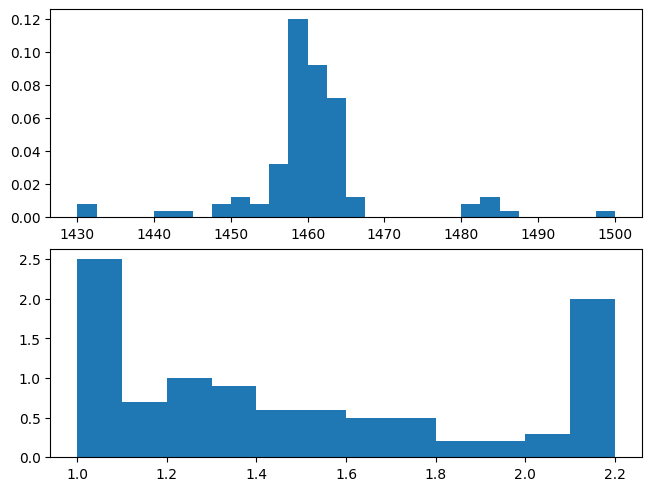

In [100]:
fig, ax = plt.subplots(2,1, layout="constrained")
ax[0].hist(sound_speed_estimate, c, density=True)
ax[1].hist(density_estimate, rho, density=True)

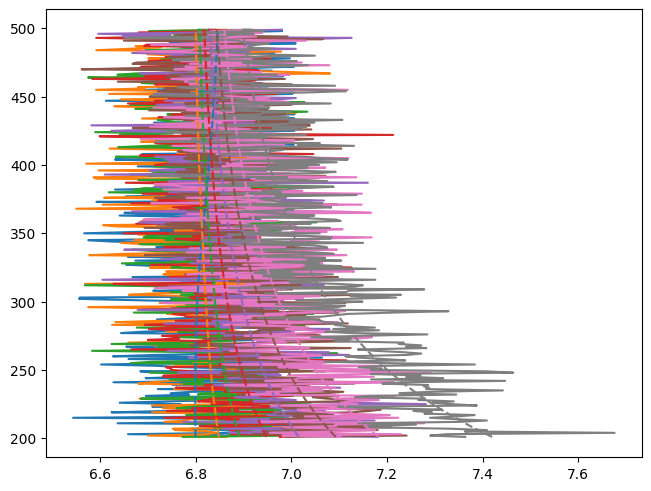

In [79]:
fig, ax = plt.subplots(layout = "constrained")

#ax.plot(noisy_atimes_data.T, f_Vg)
ax.plot(atimes_data.T, f_Vg)

#ax.plot(arrival_times_replica[c == TRUE_SOUNDSPEED, estimated].T, f_Vg, "c--")
ax.set_prop_cycle(None)
_ = ax.plot(atimes_replica[rho == TRUE_DENSITY, c == TRUE_SOUNDSPEED, selected[-1]].T, f_Vg, "--")

In [107]:
L = ai.evaluate_likelihoods(atimes_data, atimes_replica, modecomb, ai.likelihood_direct)

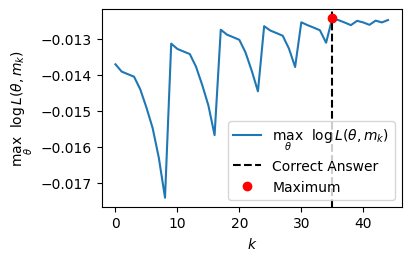

In [113]:
fig, ax = plt.subplots(layout = "constrained")

ax.plot(np.max(L, axis=(1,2))/1e3, label='$\\max_\\theta$  $ \\log L(\\theta, m_k)$')
ax.axvline(true_ind, ls='--', c='k', label='Correct Answer')
_ = ax.plot(best_modes, np.max(L)/1e3, 'ro', label='Maximum')


ax.set_ylabel("$\\max_\\theta$  $ \\log L(\\theta, m_k)$")
ax.set_xlabel("$k$")

ax.legend()

fig.set_size_inches([4,2.5])

fig.savefig('../data/output/figures/modelabel_likelihood.pdf')



In [ ]:
fig, ax = plt.subplots(layout = "constrained")

ax.plot(c, likelihood_correct)
ax.plot(c, likelihood_est)

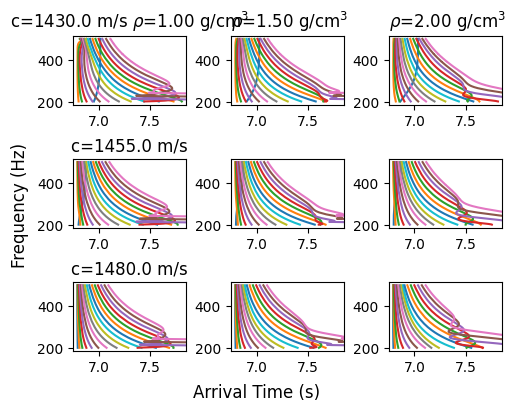

In [120]:
nstep = int(np.ceil(len(rho)/3))
mstep = int(np.ceil(len(c)/3))

atimes = arrival_times_replica[::nstep,::mstep]

fig = plt.figure(layout = "constrained")

for m in range(3):
    for n in range(3):
        i = np.ravel_multi_index((m,n), (3,3))
        ax = fig.add_subplot(3,3,i+1)
        
        ax.plot(atimes[n,m].T, f_Vg)
        ax.set_xlim([6.75, 7.85])

        title = ""
        if n==0:
            title = title + f"c={c[::mstep][m]} m/s"
        if m==0:
            title = title + f" $\\rho$={rho[::nstep][n]:1.2f} g/cm$^3$"
        ax.set_title(title)
        
fig.supylabel("Frequency (Hz)")
fig.supxlabel("Arrival Time (s)")

fig.set_size_inches([5,4])
fig.savefig("../data/output/figures/modecurves.pdf")

In [112]:
export = dict(density_estimate=density_estimate,
              sound_speed_estimate=sound_speed_estimate,
              modes_estimate=modes_estimate,
              selected=np.array(selected, dtype=object),
              modes_match=modes_match,
              atimes_data=atimes_data,
              atimes_replica=atimes_replica,
              modecomb=modecomb)

np.savez('../data/output/montecarlo_modes20261119.npz', **export)

In [115]:
modesss = [np.arange(max_modes)[m] for m in modecomb]

In [119]:
print(np.array(modesss) + 1)

[[ 2  3  4  5  6  7  8  9]
 [ 1  3  4  5  6  7  8  9]
 [ 1  2  4  5  6  7  8  9]
 [ 1  2  3  5  6  7  8  9]
 [ 1  2  3  4  6  7  8  9]
 [ 1  2  3  4  5  7  8  9]
 [ 1  2  3  4  5  6  8  9]
 [ 1  2  3  4  5  6  7  9]
 [ 1  2  3  4  5  6  7  8]
 [ 2  3  4  5  6  7  8 10]
 [ 1  3  4  5  6  7  8 10]
 [ 1  2  4  5  6  7  8 10]
 [ 1  2  3  5  6  7  8 10]
 [ 1  2  3  4  6  7  8 10]
 [ 1  2  3  4  5  7  8 10]
 [ 1  2  3  4  5  6  8 10]
 [ 1  2  3  4  5  6  7 10]
 [ 2  3  4  5  6  7  9 10]
 [ 1  3  4  5  6  7  9 10]
 [ 1  2  4  5  6  7  9 10]
 [ 1  2  3  5  6  7  9 10]
 [ 1  2  3  4  6  7  9 10]
 [ 1  2  3  4  5  7  9 10]
 [ 1  2  3  4  5  6  9 10]
 [ 2  3  4  5  6  8  9 10]
 [ 1  3  4  5  6  8  9 10]
 [ 1  2  4  5  6  8  9 10]
 [ 1  2  3  5  6  8  9 10]
 [ 1  2  3  4  6  8  9 10]
 [ 1  2  3  4  5  8  9 10]
 [ 2  3  4  5  7  8  9 10]
 [ 1  3  4  5  7  8  9 10]
 [ 1  2  4  5  7  8  9 10]
 [ 1  2  3  5  7  8  9 10]
 [ 1  2  3  4  7  8  9 10]
 [ 2  3  4  6  7  8  9 10]
 [ 1  3  4  6  7  8  9 10]
 